##### EDA and Visualization

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv(r"../data/cleaned/diwali_sales_cleaned.csv")
df["Age_Group"] = df["Age_Group"].astype("category") 
df.shape

(11239, 13)

In [4]:
total_revenue = df["Amount"].sum()
print(f"Total revenue in this dataset: {total_revenue}$")

Total revenue in this dataset: 106249132$


In [5]:
category =(
    df.groupby("Product_Category") ["Amount"]
    .agg(revenue ="sum", rows = "count")
    .sort_values("revenue", ascending= False)

)

category["share_pct"] = (category["revenue"] / category["revenue"].sum() * 100).round(2)
category

,revenue,rows,share_pct
Product_Category,,,
Food,33933883,2490,31.94
Clothing & Apparel,16495019,2655,15.52
Electronics & Gadgets,15643846,2087,14.72
Footwear & Shoes,15575209,1059,14.66
Furniture,5440052,352,5.12
Games & Toys,4331694,386,4.08
Sports Products,3635933,356,3.42
Beauty,1959484,422,1.84
Auto,1958610,97,1.84


##### Visualization

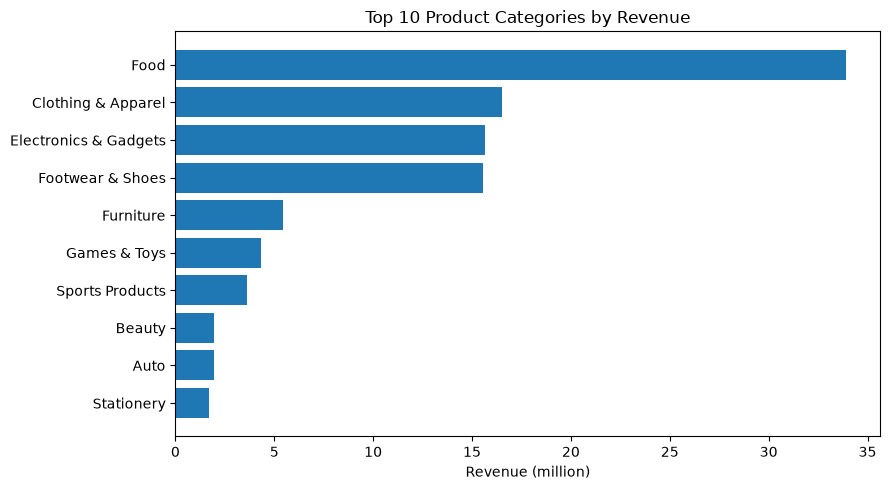

In [18]:
top10 = category.head(10).sort_values("revenue")   

plt.figure(figsize=(9, 5))
plt.barh(top10.index, top10["revenue"] / 1e6)
plt.xlabel("Revenue (million)")
plt.title("Top 10 Product Categories by Revenue")
plt.tight_layout()
plt.savefig("../images/q1_revenue_by_category.png", dpi=150)
plt.show()

<b>Food</b> products account for<b> 32%</b> of total revenue, which is more than double the revenue of the next category. The top four categories <b>(food products, apparel, electronics, and footwear)</b> generate approximately <b>77%</b> of total revenue; therefore, priority should be given to these categories regarding inventory and marketing budgets.

##### Revenue by State

In [7]:
state = (
    df.groupby("State") ["Amount"]
    .agg(revenue = "sum", rows = "count")
    .sort_values("revenue", ascending= False)
)

state["share_pct"] = (state["revenue"] / state["revenue"].sum() * 100). round(2)
state

,revenue,rows,share_pct
State,,,
Uttar Pradesh,19374968,1944,18.24
Maharashtra,14427543,1525,13.58
Karnataka,13523540,1304,12.73
Delhi,11603819,1104,10.92
Madhya Pradesh,8101142,921,7.62
Andhra Pradesh,8037147,811,7.56
Himachal Pradesh,4963368,608,4.67
Haryana,4220175,452,3.97
Bihar,4022757,434,3.79


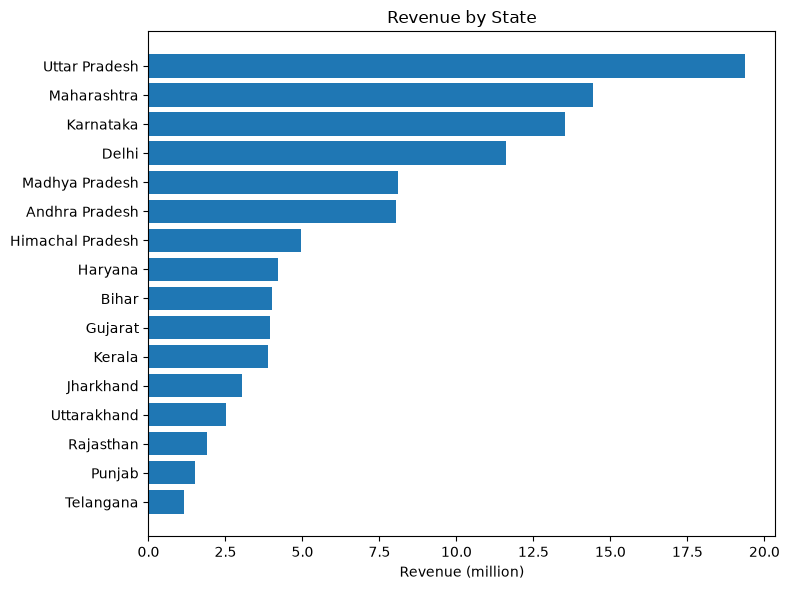

In [14]:
s = state["revenue"].sort_values() / 1e6  

plt.figure(figsize=(8, 6))
plt.barh(s.index, s.values)
plt.xlabel("Revenue (million)")
plt.title("Revenue by State")
plt.tight_layout()
plt.savefig("../images/q2_revenue_by_state.png", dpi=150)
plt.show()

In [19]:
top, bottom = state["revenue"].idxmax(), state["revenue"].idxmin()
print(top, "vs", bottom, "->", round(state["revenue"].max() / state["revenue"].min(), 1), "times")

Uttar Pradesh vs Telangana -> 16.8 times
